In [1]:
import pandas as pd 

In [2]:
df = pd.read_csv("airbnb_dirty_dataset.csv")
df

,listing_id,city,property_type,price,rating,reviews,minimum_nights,host,availability_days,last_booked
0,1000,Delhi,Apartment,5412.0,3.8,211.0,9,Host_23,302,2025-08-05
1,1001,Mumbai,Apartment,7670.0,4.3,214.0,9,NaN,332,2025-12-26
2,1002,Ahmedabad,Villa,3813.0,4.3,1100.0,7,Host_88,142,2025-03-21
3,1003,Goa,NaN,4204.0,3.9,NaN,6,NaN,135,2025-01-23
4,1004,Chennai,House,9020.0,5.0,93.0,15,Host_221,185,2025-10-23
...,...,...,...,...,...,...,...,...,...,...
995,1839,Jaipur,House,4785.0,4.1,230.0,7,Host_93,322,2025-12-07
996,1516,Bengaluru,Loft,800.0,NaN,NaN,13,Host_125,153,2025-05-09
997,1389,Chennai,Villa,NaN,3.6,134.0,6,Host_42,132,2025-12-19
998,1921,Mumbai,Studio,4318.0,3.2,315.0,7,Host_211,296,2025-12-02


<Axes: >

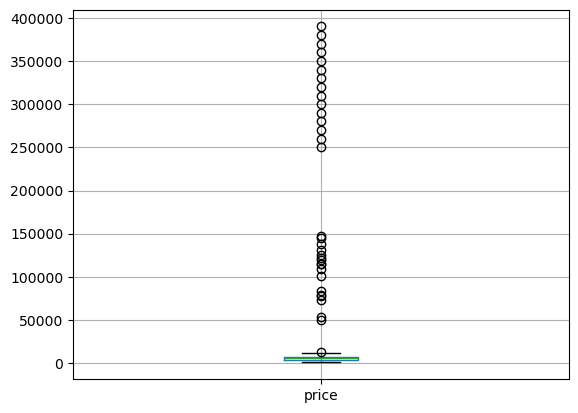

In [3]:
df.boxplot(column="price")

In [4]:
# outliers  :
lq = df["price"].quantile(0.25)
lq

np.float64(3922.5)

In [5]:
uq = df["price"].quantile(0.75)
uq

np.float64(7279.5)

In [6]:
# iqr   : interquantile range
iqr = uq - lq
iqr

np.float64(3357.0)

In [7]:
lowerBound = lq - 1.5*iqr
lowerBound

np.float64(-1113.0)

In [8]:
upperBound = uq + 1.5*iqr
upperBound

np.float64(12315.0)

In [9]:
# show the outliers :
df[(df["price"] < lowerBound) | (df["price"] > upperBound)]

,listing_id,city,property_type,price,rating,reviews,minimum_nights,host,availability_days,last_booked
24,1024,Chennai,House,310000.0,4.6,150.0,13,Host_218,121,2025-03-27
83,1083,Delhi,Villa,109048.0,NaN,46.0,1,Host_60,147,2025-12-28
108,1108,Bengaluru,Apartment,340000.0,4.4,72.0,5,Host_117,154,2025-04-12
110,1110,Ahmedabad,Studio,300000.0,4.3,271.0,12,Host_128,146,2025-04-28
140,1140,Delhi,NaN,280000.0,4.9,186.0,7,Host_125,310,2025-08-15
148,1148,Delhi,House,320000.0,4.1,101.0,14,Host_38,120,2025-02-22
170,1170,Chennai,Loft,78266.0,3.5,164.0,12,Host_156,270,2025-08-05
260,1260,Chennai,Apartment,119391.0,4.2,104.0,5,NaN,257,2025-12-24
318,1318,Pune,Villa,270000.0,4.9,29.0,5,Host_200,353,2025-01-14
326,1326,Bengaluru,Apartment,115065.0,NaN,201.0,13,Host_211,132,2025-03-27


In [10]:
# remove outliers  :
df_clean = df[(df["price"] >= lowerBound) & (df["price"] <= upperBound)]

In [11]:
df_clean

,listing_id,city,property_type,price,rating,reviews,minimum_nights,host,availability_days,last_booked
0,1000,Delhi,Apartment,5412.0,3.8,211.0,9,Host_23,302,2025-08-05
1,1001,Mumbai,Apartment,7670.0,4.3,214.0,9,NaN,332,2025-12-26
2,1002,Ahmedabad,Villa,3813.0,4.3,1100.0,7,Host_88,142,2025-03-21
3,1003,Goa,NaN,4204.0,3.9,NaN,6,NaN,135,2025-01-23
4,1004,Chennai,House,9020.0,5.0,93.0,15,Host_221,185,2025-10-23
...,...,...,...,...,...,...,...,...,...,...
993,1893,Chennai,Apartment,3101.0,4.0,105.0,1,Host_235,17,2025-07-13
994,1022,Ahmedabad,Loft,2020.0,4.4,151.0,7,NaN,173,2025-02-25
995,1839,Jaipur,House,4785.0,4.1,230.0,7,Host_93,322,2025-12-07
996,1516,Bengaluru,Loft,800.0,NaN,NaN,13,Host_125,153,2025-05-09


In [12]:
df_clean.to_csv("cleanedAirBnb.csv")

In [13]:
# 21. Find the cheapest property.
print(df[df["price"]== df["price"].min()])

     listing_id       city property_type  price  rating  reviews  \
49         1049     Jaipur         House  800.0     4.0     98.0   
137        1137     Mumbai         House  800.0     4.4     71.0   
189        1189       Pune     Apartment  800.0     4.1   1000.0   
202        1202  Ahmedabad         House  800.0     4.8    183.0   
203        1203    Chennai         House  800.0     4.6     63.0   
290        1290  Bengaluru        Studio  800.0     3.7     83.0   
304        1304     Jaipur        Studio  800.0     NaN    224.0   
332        1332       Pune     Apartment  800.0     4.2    186.0   
333        1333     Jaipur        Studio  800.0     3.7    138.0   
378        1378  Bengaluru     Apartment  800.0     4.9    218.0   
381        1381     Jaipur         House  800.0     4.5     81.0   
417        1417     Jaipur          Loft  800.0     4.6      0.0   
516        1516  Bengaluru          Loft  800.0     NaN      NaN   
599        1599  Ahmedabad     Apartment  800.0 

In [14]:
# 22. Sort by price (ascending).
print(df.sort_values(by ="price"))

     listing_id       city property_type  price  rating  reviews  \
189        1189       Pune     Apartment  800.0     4.1   1000.0   
924        1924       Pune         Villa  800.0     4.7      0.0   
888        1888     Mumbai        Studio  800.0     4.9     86.0   
516        1516  Bengaluru          Loft  800.0     NaN      NaN   
137        1137     Mumbai         House  800.0     4.4     71.0   
..          ...        ...           ...    ...     ...      ...   
875        1875     Jaipur         House    NaN     3.4      0.0   
880        1880    Chennai          Loft    NaN     4.0    135.0   
892        1892        Goa     Apartment    NaN     4.4    156.0   
997        1389    Chennai         Villa    NaN     3.6    134.0   
999        1494      Delhi         Villa    NaN     4.2     39.0   

     minimum_nights      host  availability_days last_booked  
189               3  Host_183                363  2025-12-25  
924               1   Host_96                 71  2025-10

In [15]:
# 23. Sort by price (descending).
print(df.sort_values(by ="price" ,ascending = False) )

     listing_id     city property_type     price  rating  reviews  \
804        1804      Goa         House  390000.0     4.2   1600.0   
484        1484   Jaipur         Villa  380000.0     3.7     77.0   
713        1713   Jaipur         Villa  370000.0     4.6     28.0   
932        1932  Chennai     Apartment  360000.0     4.9    161.0   
954        1954   Mumbai           NaN  350000.0     4.3    126.0   
..          ...      ...           ...       ...     ...      ...   
875        1875   Jaipur         House       NaN     3.4      0.0   
880        1880  Chennai          Loft       NaN     4.0    135.0   
892        1892      Goa     Apartment       NaN     4.4    156.0   
997        1389  Chennai         Villa       NaN     3.6    134.0   
999        1494    Delhi         Villa       NaN     4.2     39.0   

     minimum_nights      host  availability_days last_booked  
804               4  Host_197                255  2025-12-13  
484               7       NaN                

In [16]:
# 24. Display the top 10 most expensive properties.
print(df.sort_values(by="price", ascending=False).head(10))

     listing_id       city property_type     price  rating  reviews  \
804        1804        Goa         House  390000.0     4.2   1600.0   
484        1484     Jaipur         Villa  380000.0     3.7     77.0   
713        1713     Jaipur         Villa  370000.0     4.6     28.0   
932        1932    Chennai     Apartment  360000.0     4.9    161.0   
954        1954     Mumbai           NaN  350000.0     4.3    126.0   
108        1108  Bengaluru     Apartment  340000.0     4.4     72.0   
361        1361     Jaipur        Studio  330000.0     4.0      0.0   
148        1148      Delhi         House  320000.0     4.1    101.0   
24         1024    Chennai         House  310000.0     4.6    150.0   
110        1110  Ahmedabad        Studio  300000.0     4.3    271.0   

     minimum_nights      host  availability_days last_booked  
804               4  Host_197                255  2025-12-13  
484               7       NaN                 55  2025-01-09  
713              11  Host_204

In [17]:
# 25. Display the top 10 cheapest properties.
print(df.sort_values(by = "price",ascending = True).head(10))

     listing_id       city property_type  price  rating  reviews  \
189        1189       Pune     Apartment  800.0     4.1   1000.0   
924        1924       Pune         Villa  800.0     4.7      0.0   
888        1888     Mumbai        Studio  800.0     4.9     86.0   
516        1516  Bengaluru          Loft  800.0     NaN      NaN   
137        1137     Mumbai         House  800.0     4.4     71.0   
202        1202  Ahmedabad         House  800.0     4.8    183.0   
203        1203    Chennai         House  800.0     4.6     63.0   
772        1772     Jaipur          Loft  800.0     4.3    159.0   
996        1516  Bengaluru          Loft  800.0     NaN      NaN   
417        1417     Jaipur          Loft  800.0     4.6      0.0   

     minimum_nights      host  availability_days last_booked  
189               3  Host_183                363  2025-12-25  
924               1   Host_96                 71  2025-10-23  
888               6  Host_133                 22  2025-04-25  

In [18]:
# 26. Find Villas costing above 80,000.
print(df[(df["property_type"] == "Villa") & (df["price"] > 80000)])

     listing_id    city property_type     price  rating  reviews  \
83         1083   Delhi         Villa  109048.0     NaN     46.0   
318        1318    Pune         Villa  270000.0     4.9     29.0   
484        1484  Jaipur         Villa  380000.0     3.7     77.0   
601        1601     NaN         Villa   83175.0     4.8    126.0   
625        1625  Jaipur         Villa  290000.0     4.4     33.0   
643        1643  Jaipur         Villa  250000.0     4.3    125.0   
713        1713  Jaipur         Villa  370000.0     4.6     28.0   

     minimum_nights      host  availability_days last_booked  
83                1   Host_60                147  2025-12-28  
318               5  Host_200                353  2025-01-14  
484               7       NaN                 55  2025-01-09  
601               8  Host_140                  2  2025-11-08  
625               3   Host_19                159  2025-11-10  
643              12  Host_227                249  2025-12-03  
713           

In [19]:
# 27. Find Apartments in Delhi with rating above 4.5.
print(df[(df["property_type"] == "Apartment") & (df["city"] == "Delhi") & (df["rating"] > 4.5)])

     listing_id   city property_type   price  rating  reviews  minimum_nights  \
342        1342  Delhi     Apartment     NaN     4.8    113.0              14   
786        1786  Delhi     Apartment  6951.0     4.7    177.0              14   
870        1870  Delhi     Apartment  6579.0     5.0      3.0               7   
910        1910  Delhi     Apartment  8576.0     5.0    144.0               6   

         host  availability_days last_booked  
342  Host_220                167  2025-03-17  
786  Host_153                351  2025-07-30  
870  Host_244                 58  2025-05-18  
910   Host_82                306  2025-08-08  


In [20]:
# 28. Add a new column review_per_rating.
# print(df[["price", "Bedrooms", "Price_per_Bedroom"]].head())

df["review_per_rating"] = df["reviews"] / df["rating"]

In [21]:
df

,listing_id,city,property_type,price,rating,reviews,minimum_nights,host,availability_days,last_booked,review_per_rating
0,1000,Delhi,Apartment,5412.0,3.8,211.0,9,Host_23,302,2025-08-05,55.526316
1,1001,Mumbai,Apartment,7670.0,4.3,214.0,9,NaN,332,2025-12-26,49.767442
2,1002,Ahmedabad,Villa,3813.0,4.3,1100.0,7,Host_88,142,2025-03-21,255.813953
3,1003,Goa,NaN,4204.0,3.9,NaN,6,NaN,135,2025-01-23,NaN
4,1004,Chennai,House,9020.0,5.0,93.0,15,Host_221,185,2025-10-23,18.600000
...,...,...,...,...,...,...,...,...,...,...,...
995,1839,Jaipur,House,4785.0,4.1,230.0,7,Host_93,322,2025-12-07,56.097561
996,1516,Bengaluru,Loft,800.0,NaN,NaN,13,Host_125,153,2025-05-09,NaN
997,1389,Chennai,Villa,NaN,3.6,134.0,6,Host_42,132,2025-12-19,37.222222
998,1921,Mumbai,Studio,4318.0,3.2,315.0,7,Host_211,296,2025-12-02,98.437500


In [ ]:
S